# **<center>Simple Linear Regression</center>**

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\archive (1)\placement.csv")

In [3]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [4]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'PACKAGE(LPA)')

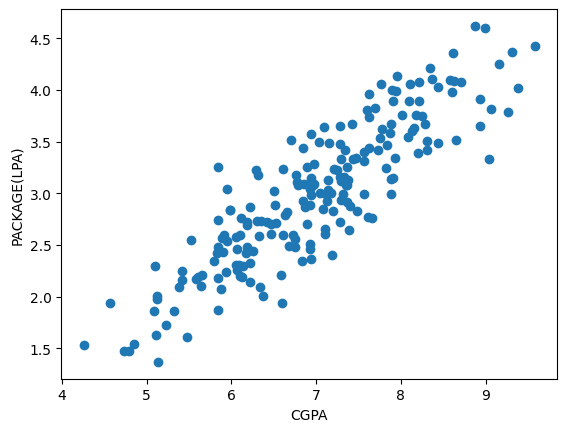

In [5]:
plt.scatter(x=df['cgpa'], y=df['package'])
plt.xlabel('CGPA')
plt.ylabel('PACKAGE(LPA)')

In [6]:
# spliting independent and dependent features
x= df.iloc[:,:1] 
y = df.iloc[:,1:]

In [7]:
# split on basis of train test split
from sklearn.model_selection import  train_test_split

In [8]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [9]:
from sklearn.linear_model import LinearRegression

In [10]:
lr  = LinearRegression()

In [11]:
lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [12]:
f=lr.predict(x_test)
y_o = pd.Series(y_test.squeeze())

In [13]:
predicted_df = pd.DataFrame({'CGPA': x_test.squeeze(),
              'Original Package':y_test.squeeze(),
              'Predicted Package':f.flatten()})

In [14]:
package = predicted_df.reset_index(drop=True)

Text(0.5, 0, 'Package(LPA)')

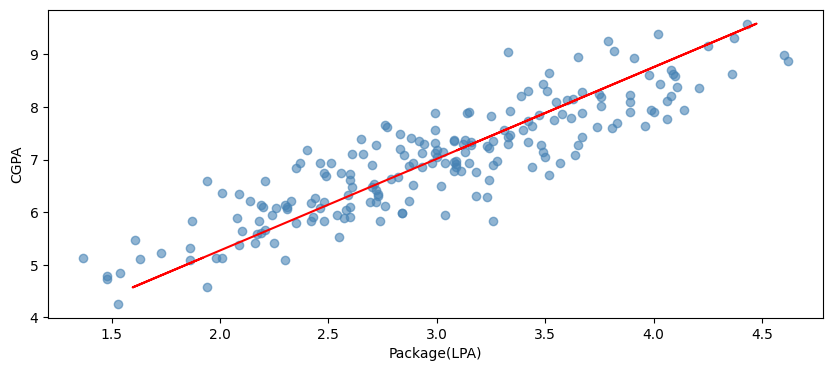

In [15]:
plt.figure(figsize=(10,4))
plt.scatter(x=df['package'],y=df['cgpa'],color='steelblue',alpha=0.6)
plt.plot(lr.predict(x_train),x_train,color = 'red')
plt.ylabel('CGPA')
plt.xlabel('Package(LPA)')

In [16]:
m= lr.coef_ # slope # tells weightage
b = lr.intercept_ # intercept

In [17]:
# y = mx + c
m*7.09 +  b

array([[3.04447145]])

# **Regression Metrices**

- MAE
- MSE
- RMSE
- R2 SCORE
- ADJESTED R2 SCORE

In [18]:
from sklearn.metrics import mean_squared_error, r2_score , mean_absolute_error

In [ ]:
print("MAE: ",mean_absolute_error(y_test,f))
print("MSE: ",mean_squared_error(y_test,f))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,f)))
print("R2_score",r2_score(y_test,f))

MAE:  0.23150985393278373
MSE:  0.08417638361329656
RMSE:  0.2901316659954521
R2_score 0.7730984312051673


In [28]:
# adjested r2_score 
r2 = r2_score(y_test,f)
n = df['cgpa'].count()
k = 1

In [29]:
adj_r2 = 1 - (((1-r2)*(n-1))/(n-1-k))

In [30]:
adj_r2

np.float64(0.7719524636860015)